# Parameter estimation of one compact binary

Every extrinsic parameter is marginalized in closed form through the tables, so parameter estimation is a grid sweep of table lookups over $(\mathcal{M}_c, q, \chi_{\rm eff})$.


In [1]:
import sys, pathlib, time
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT/'src')); sys.path.insert(0, str(ROOT/'examples'))
import numpy as np, matplotlib.pyplot as plt
from tqdm import tqdm                      # plain text bar: renders in any front end
from exmarg import figstyle, make_event, make_data
from exmarg.evaluate import SumEvaluator, zeta, mc_q_to_m1m2
from fetch_tables import ensure_nodes
figstyle.apply()
get_ipython().run_line_magic("matplotlib","inline")

/projects/standard/vuk/shared/boyb001/non_gaussian/exmarg/src/exmarg/profiles.py:14: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## 1. Data generation

A synthetic injection at network SNR $\rho\approx 18$, loud enough that the single-event posterior localizes.

In [2]:
mc_true, q_true, chi_true = 28.0, 0.8, 0.1
m1, m2 = mc_q_to_m1m2(mc_true, q_true)
case = make_event(m1, m2, chi_true, chi_true, 4.0, 25.0, 512.0, sky=(1.2,2.0), psi_s=0.4, chi_s=0.3)
RHO = 18.0
d = make_data(case, seed=12345, inject=True, phi_s=0.7, t_s=2.0, y_s=RHO/case.rho_mf)
print('injected network SNR = %.1f' % RHO)

injected network SNR = 18.0


The matched-filter series $z_I(t)$ against the true template peaks at the arrival time; its height is the SNR.

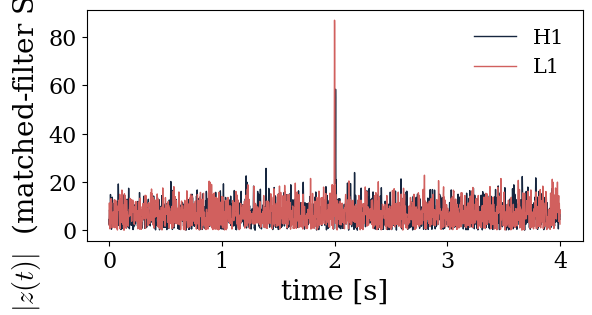

In [3]:
t, z = zeta(case, {'H': d['H'].astype(complex), 'L': d['L'].astype(complex)})
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for I, col in [('H', figstyle.NAVY), ('L', figstyle.RED)]:
    ax.plot(t, np.abs(z[I]), color=col, lw=1.0, label='%s1' % I)
ax.set_xlabel('time [s]'); ax.set_ylabel(r'$|z(t)|$  (matched-filter SNR)')
ax.legend(frameon=False, fontsize=figstyle.FS_LEGEND); plt.show()

## 2. The grid and its tables

We load a compact grid of loudness nodes.

In [4]:
mc_ax = np.linspace(26.5, 29.5, 12)
q_ax = np.linspace(0.6, 1.0, 6)
x_ax = np.linspace(-0.2, 0.2, 6)
us = []
for mc in (mc_ax[0], mc_ax[-1]):
    for q in (q_ax[0], q_ax[-1]):
        for chi in (x_ax[0], x_ax[-1]):
            mm1, mm2 = mc_q_to_m1m2(mc, q)
            cc = make_event(mm1, mm2, chi, chi, 4.0, 25.0, 512.0, sky=(1.2,2.0), psi_s=0.4, chi_s=0.3)
            us.append(cc.u['H'])
stems = ensure_nodes(u_lo=min(us)*0.95, u_hi=max(us)*1.05)
print('%d templates, %d table nodes' % (mc_ax.size*q_ax.size*x_ax.size, len(stems)))

432 templates, 7 table nodes


## 3. Load the tables into memory

We cache the tables by reading them into memory.

In [5]:
ev = SumEvaluator(case, d, stems, tc=2.0, dt=0.55)
t0 = time.time()
for k in ev.kernels:
    k.lnS = np.array(k.lnS)        # load the memory-mapped tables into RAM once
print('tables loaded into RAM (%.0f s); each template now scores in a few ms' % (time.time()-t0))

tables loaded into RAM (11 s); each template now scores in a few ms


## 4. Sweep the grid

A serial sweep with a live progress bar; each call is a table lookup.

In [6]:
pts = [(i, j, k) for i in range(mc_ax.size) for j in range(q_ax.size) for k in range(x_ax.size)]
cube = np.empty((mc_ax.size, q_ax.size, x_ax.size))
for (i, j, k) in tqdm(pts, desc='scoring grid'):
    mm1, mm2 = mc_q_to_m1m2(mc_ax[i], q_ax[j])
    cube[i, j, k] = ev.lnlam(mm1, mm2, x_ax[k])
imax = np.unravel_index(cube.argmax(), cube.shape)
print('ln Lambda max %.1f at Mc=%.1f q=%.2f chi=%+.2f'
      % (cube.max(), mc_ax[imax[0]], q_ax[imax[1]], x_ax[imax[2]]))

scoring grid:   0%|          | 0/432 [00:00<?, ?it/s]

scoring grid:   0%|          | 1/432 [00:02<16:45,  2.33s/it]

scoring grid:   0%|          | 2/432 [00:02<08:06,  1.13s/it]

scoring grid:   1%|          | 3/432 [00:02<04:50,  1.47it/s]

scoring grid:   1%|          | 4/432 [00:02<03:18,  2.16it/s]

...

scoring grid:  99%|█████████▉| 427/432 [00:34<00:00, 15.14it/s]

scoring grid:  99%|█████████▉| 429/432 [00:35<00:00, 15.26it/s]

scoring grid: 100%|█████████▉| 431/432 [00:35<00:00, 15.44it/s]

scoring grid: 100%|██████████| 432/432 [00:35<00:00, 12.24it/s]

ln Lambda max 124.7 at Mc=28.4 q=1.00 chi=+0.12


## 5. Posterior

Flat-prior marginals and contours, truth in red.

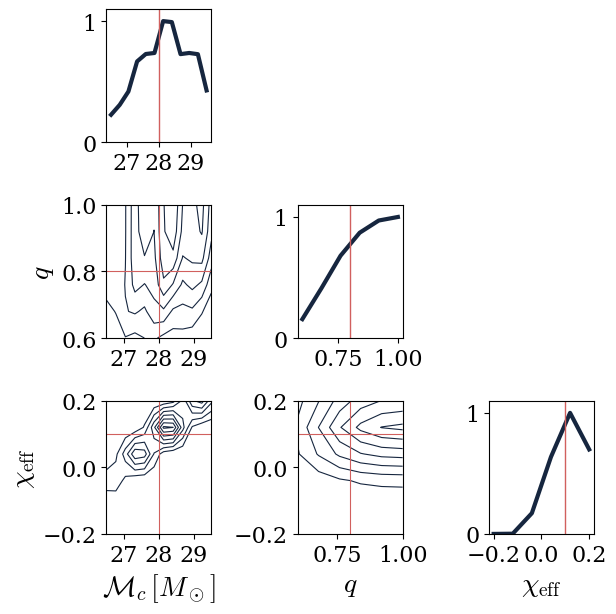

In [7]:
P = np.exp(cube - cube.max())
axes = [mc_ax, q_ax, x_ax]
labels = [r'$\mathcal{M}_c\,[M_\odot]$', r'$q$', r'$\chi_{\rm eff}$']
truth = [mc_true, q_true, chi_true]; NAVY, RED = figstyle.NAVY, figstyle.RED
fig, ax = plt.subplots(3, 3, figsize=(6.4, 6.4))
for a in range(3):
    for b in range(3):
        if b > a: ax[a, b].axis('off'); continue
        if a == b:
            m = P.sum(axis=tuple(t for t in range(3) if t != a)); m /= m.max()
            ax[a, b].plot(axes[a], m, color=NAVY); ax[a, b].axvline(truth[a], color=RED, lw=1.0); ax[a, b].set_ylim(0, 1.1)
        else:
            m = P.sum(axis=[t for t in range(3) if t not in (a, b)][0])
            ax[a, b].contour(axes[b], axes[a], m.T, colors=NAVY, linewidths=0.8)
            ax[a, b].axvline(truth[b], color=RED, lw=0.8); ax[a, b].axhline(truth[a], color=RED, lw=0.8)
        if a == 2: ax[a, b].set_xlabel(labels[b])
        if b == 0 and a != 0: ax[a, b].set_ylabel(labels[a])
fig.tight_layout()
np.savez('data/fig7_pe.npz', cube=cube, mc_ax=mc_ax, q_ax=q_ax, x_ax=x_ax, truth=truth)
plt.show()